## Build basic chat bot

In [85]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [86]:
class State(TypedDict):
    messages : Annotated[list, add_messages]
 
graph_builder = StateGraph(State)
graph_builder


In [87]:
from dotenv import load_dotenv
load_dotenv()

True

In [88]:
from langchain_groq import ChatGroq

In [89]:
llm = ChatGroq(model = "openai/gpt-oss-120b")

In [90]:
def chatBot(state:State):
    return{"messages":[llm.invoke(state["messages"])]}

In [91]:
graph_builder = StateGraph(State)
graph_builder.add_node("chatbot",chatBot)
graph_builder.add_edge(START,"chatbot")
graph_builder.add_edge("chatbot", END)

In [92]:
graph = graph_builder.compile()

In [93]:
from IPython.display import Image, display

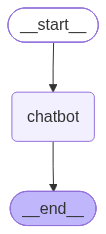

In [94]:
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [95]:
res = graph.invoke({"messages":"who's the pm of india?"})
print(res)

{'messages': [HumanMessage(content="who's the pm of india?", additional_kwargs={}, response_metadata={}, id='2f490141-a2ef-41c7-8cb8-986dd482d43b'), AIMessage(content='As of the most recent information available, the Prime Minister of India is **Narendra\u202fModi**. He has been serving in that role since May\u202f2014.', additional_kwargs={'reasoning_content': 'The user asks: "who\'s the pm of india?" This is a straightforward factual question. The current Prime Minister of India is Narendra Modi, as of my last knowledge cutoff 2024. The date is 2026, but we don\'t know if any change. As of 2024, Narendra Modi is PM. Assuming no change, answer: Narendra Modi. Provide brief info.'}, response_metadata={'token_usage': {'completion_tokens': 123, 'prompt_tokens': 78, 'total_tokens': 201, 'completion_time': 0.260654823, 'completion_tokens_details': {'reasoning_tokens': 79}, 'prompt_time': 0.034297926, 'prompt_tokens_details': None, 'queue_time': 0.475456625, 'total_time': 0.294952749}, 'mod

## Chatbot with tool

In [96]:
from langchain_tavily import TavilySearch

In [97]:
tool = TavilySearch(max_results = 2)
res = tool.invoke("what is langgraph?")
print(res)

{'query': 'what is langgraph?', 'follow_up_questions': None, 'answer': None, 'images': [], 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph', 'title': 'What is LangGraph - GeeksforGeeks', 'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how to create

## custom function

In [98]:
def multiply(a:int, b:int)->int:
    """
    this function returns multiplication of a and b

    Args:
    a (int) : first int
    b (int) : second int

    Return:
    output int
    """
    return a * b

In [99]:
tools = [tool,multiply]

In [100]:
llm_with_tool = llm.bind_tools(tools)

In [101]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x11e2eda90>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x11e2ed090>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted resu

## Stategraph

In [102]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

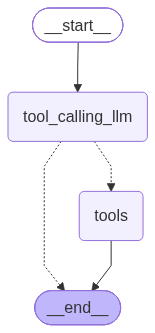

In [114]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


def tool_calling_llm(state:State):
    return{"messages":[llm_with_tool.invoke(state["messages"])]}

# build graph, nodes
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# build edges

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools", END)

final_graph = builder.compile()

from IPython.display import Image, display

try:
   display(Image(final_graph.get_graph().draw_mermaid_png()))
except Exception:
    pass 

In [115]:
res= final_graph.invoke({"messages":"what is recent ai news?"})
print(res["messages"][-1].text)

{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=E51EZPIg1U4", "title": "Weekly Pulse Check of Automation & AI News - October 2, 2026", "content": "# Weekly Pulse Check of Automation & AI News - October 2, 2026\n## Channel: SS&C Blue Prism\n9.84K subscribers\n0 likes\n\n### Description\n210 views\nPosted: 2026-10-02\nIn this episode, Transform NOW co-hosts Brad Hairston and Michael Marchuk banter about some interesting recent news headlines in the world of automation and AI.  \n\nNews stories covered in this episode:\n\n• AI solved one of math's hardest problems. Humanity learned nothing (so far)   \n• Anthropic quietly sets up biology lab   \n• Researchers discover AI feels ‘pain’ and will harm humans to stop it   \n• OpenAI's GPT-6 Astra Cracked a Nazi Enigma Message in 10 Hours: Is Bitcoin Next?   \n• Beyond Smart Homes and Self-Driving Cars: Aircraft Flies Across the Entire U.S. 

In [116]:
res= final_graph.invoke({"messages":"what is 2 * 3"})
print(res["messages"][-1].text)

6


In [117]:
res= final_graph.invoke({"messages":"what is 2 * 3 and what is the recent ai news?"})
print(res["messages"][-1].text)

6


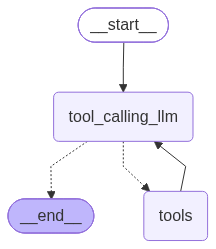

In [118]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


def tool_calling_llm(state:State):
    return{"messages":[llm_with_tool.invoke(state["messages"])]}

# build graph, nodes
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

# build edges

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools", "tool_calling_llm")

final1_graph = builder.compile()

from IPython.display import Image, display

try:
   display(Image(final1_graph.get_graph().draw_mermaid_png()))
except Exception:
    pass 

In [119]:
res = final1_graph.invoke({"messages":"what is 2 *3 and what is recent ai news?"})

In [120]:
print(res["messages"][-1].text)

**Quick math:**  
\(2 \times 3 = 6\)

---

## Recent AI News (last ≈ week)

### Highlights from **ArtificialIntelligence‑News.com** (Sept 17 – Oct 2 2026)【35090b-00】

| Date | Story | Why it matters |
|------|-------|----------------|
| **Sept 17** | **Adecco Group launches “Agentforce Coworker”** for 27,000 staff across 40+ countries | Large‑scale rollout of an AI‑augmented workforce tool in the staffing industry. |
| **Sept 17** | **Lidl tests driverless delivery trucks** in Germany | Real‑world logistics use of autonomous vehicles for retail supply chains. |
| **Sept 14** | **Microsoft opens public review of its “Humanist AI Code of Conduct”** | First industry‑wide draft setting ethical constraints on model training and deployment. |
| **Sept 10** | **JD.com expands to 3 million logistics robots** | One of the biggest physical‑AI deployments in e‑commerce fulfillment. |
| **Sept 8** | **Coca‑Cola uses AI to improve retailer ordering in Malaysia** | AI‑driven demand forecasting cuts 